In [1]:
!cp -r ../../data/upsampled_validation/video_00005 input_video

In [38]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import glob
import cv2
import os
import imageio
from tqdm import tqdm
import imageio
import torch
import matplotlib.pyplot as plt
import numpy as np
import glob
import cv2
import os
import imageio
from esim_torch import SiliconRetinaFloatCUDAOnline , SiliconRetinaConfig
from IPython.display import Video
from tqdm import tqdm


def make_vis(pos, neg):
    pos = pos.detach().cpu().numpy()
    neg = neg.detach().cpu().numpy()
    ret = np.zeros_like(pos)
    ret = np.repeat(ret[..., None], axis=-1, repeats=3)
    
    ret[..., 0] = pos * 255
    ret[..., 2] = neg  * 255
    
    return ret.astype(np.uint8)

def rgb_to_gray(rgb):
    r, g, b = rgb[:,:,0], rgb[:,:,1], rgb[:,:,2]
    gray = 0.2989 * r + 0.5870 * g + 0.1140 * b
    return gray

# Read the datapoint

In [27]:
import os 
import json

print(os.getcwd())
print(os.listdir("."))

def read_datapoint(read_of : bool):
    frames = []
    name = None
    timestamps = None

    with open("input_video/params.json", "r") as f:
        params = json.loads(f.read())

    if read_of:
        name = 'input_video/video_upsampled_using_optical_flow.mp4'
        timestamps = params["timestamps_OF"]
        number_of_interpolated_frames = params["new_images_per_pair_OF"]
    else:
        name = 'input_video/video_upsampled_fps_eq_200.mp4'
        timestamps = params["timestamps_FF"]
        number_of_interpolated_frames = params["new_images_per_pair_FF"]
        
    with imageio.get_reader(name) as reader:
        for im in reader:
            frames.append(rgb_to_gray(im))
            
    frames = np.array(frames)
    
    return name, frames / 255.0, timestamps, number_of_interpolated_frames, params


name, frames, timestamps, number_of_interpolated_frames, params = read_datapoint(read_of=False)

Video(name)

/home/mlew/PROJS/sillicon-retina/src/neural_network/prototyping/event_representation
['test.mp4', 'vis.ipynb', 'input_video']


/tmp/ipykernel_85624/1355786134.py:34: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  gray = 0.2989 * r + 0.5870 * g + 0.1140 * b


# run pipeline

In [ ]:
# do silicon retina config
config = SiliconRetinaConfig()
config.HPF2_mode = 1
config.HPF2_param = 0.5

root = "."
T = len(frames)

def make_vis(pos, neg):
    pos = pos.detach().cpu().numpy()
    neg = neg.detach().cpu().numpy()
    ret = np.zeros_like(pos)
    ret = np.repeat(ret[..., None], axis=-1, repeats=3)
    
    ret[..., 0] = pos * 255
    ret[..., 2] = neg  * 255
    
    return ret.astype(np.uint8)
    

imgs = torch.Tensor(frames).to("cuda:0")

model = SiliconRetinaFloatCUDAOnline(config, height=imgs.shape[1], width=imgs.shape[2])
    
positive, negative = [], []

orignal_FPS = params["fps"]
    
model.reset()
for t in range(1, T+1, 1):

    input = imgs[t-1][None]
    p, n = model(input, t)
    positive.append((p.clone()[0]))
    negative.append((n.clone()[0]))

positive = torch.stack(positive, dim=0)
negative = torch.stack(negative, dim=0)

print(positive.shape, negative.shape)
#  [430, 180, 240], [430, 180, 240]

print(len(timestamps))
# 430

original_frames = np.load(f"input_video/{params['raw_images']}")["raw_images"]
print(original_frames.shape)
# (58, 180, 240)

with imageio.get_writer(os.path.join(root, 'test.mp4'), fps=30) as writer:
    for i in range(len(positive)):
        frame = make_vis(positive[i], negative[i])
        writer.append_data(frame)
        
Video("test.mp4")

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (240, 180) to (240, 192) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


torch.Size([430, 180, 240]) torch.Size([430, 180, 240])
430
(58, 180, 240)


# Exploring different encodings

In [43]:
import math, os
import numpy as np 
import torch 
import torch.nn.functional as F

import matplotlib.pyplot as plt

def to_ns(timestamps):
    """Convert timestamps to int64 nanoseconds, tolerant to seconds or ms inputs."""
    ts = np.asarray(timestamps).astype(np.float64)
    m = ts.max()
    if m < 1e6:      # assume seconds
        ts_ns = (ts * 1e9).astype(np.int64)
    elif m < 1e12:   # assume micro/milliseconds-ish (rare)
        # heuristic: if max between 1e6 and 1e12, choose scaling that brings to ns range
        scale = 1e3 if m < 1e9 else 1.0
        ts_ns = (ts * scale).astype(np.int64)
    else:            # already ns
        ts_ns = ts.astype(np.int64)
    # rebase to start at 0 for numerical stability
    ts_ns = ts_ns - ts_ns[0]
    return torch.from_numpy(ts_ns)

def make_tbounds_from_fps(num_origin_frames, fps, t0_ns=0):
    dt_ns = int(round(1e9 / float(fps)))
    
    bounds = torch.zeros((num_origin_frames - 1, 2), dtype=torch.int64)
    for k in range(num_origin_frames - 1):
        bounds[k, 0] = t0_ns + k * dt_ns
        bounds[k, 1] = t0_ns + (k + 1) * dt_ns
    
    return bounds 

def bitmaps_to_events(pos: torch.Tensor, neg: torch.Tensor, ts_ns: torch.Tensor):
    """
    pos/neg: (T,H,W) byte/bool/float {0,1}; ts_ns: (T,) int64 nanoseconds (monotonic)
    Returns x,y,t,p (all 1D tensors, sorted by t). p in {+1,-1} int8.
    """
    T,H,W = pos.shape
    # linearize nonzeros once (on CPU for memory headroom, if needed)
    on_idx  = pos.view(T,-1).nonzero(as_tuple=False)
    off_idx = neg.view(T,-1).nonzero(as_tuple=False)

    def unpack(idx2d):
        t_idx = idx2d[:,0]
        pix   = idx2d[:,1]
        t     = ts_ns.index_select(0, t_idx)
        y     = (pix // W).to(torch.int32)
        x     = (pix %  W).to(torch.int32)
        return x, y, t

    x_on,y_on,t_on     = unpack(on_idx)
    x_off,y_off,t_off  = unpack(off_idx)

    p_on  = torch.ones_like(x_on,  dtype=torch.int8)
    p_off = -torch.ones_like(x_off, dtype=torch.int8)

    x = torch.cat([x_on,  x_off],  dim=0)
    y = torch.cat([y_on,  y_off],  dim=0)
    t = torch.cat([t_on,  t_off],  dim=0)
    p = torch.cat([p_on,  p_off],  dim=0)

    order = torch.argsort(t, stable=True)
    return x[order], y[order], t[order], p[order]


# ------- Encoders (5 channels each) -------

def spike_trace_bank5(x, y, t, p, t_bounds, H, W,
                      tau_fast_ms=20.0, tau_slow_ms=80.0, tau_ts_ms=50.0,
                      asinh_k=0.0):
    """
    Channels: [ON_fast, ON_slow, OFF_fast, OFF_slow, RecencyTS]
    All derived from spikes only. Returns (K,5,H,W) float32.
    """
    K = t_bounds.shape[0]
    out = torch.zeros((K,5,H,W), dtype=torch.float32, device=x.device)

    tau_f_ns  = tau_fast_ms * 1e6
    tau_s_ns  = tau_slow_ms * 1e6
    tau_ts_ns = tau_ts_ms   * 1e6

    on_fast  = torch.zeros((H,W), dtype=torch.float32, device=x.device)
    on_slow  = torch.zeros_like(on_fast)
    off_fast = torch.zeros_like(on_fast)
    off_slow = torch.zeros_like(on_fast)

    very_old = t_bounds[0,0].item() - 10_000_000_000
    last_on  = torch.full((H,W), very_old, dtype=torch.int64, device=x.device)
    last_off = torch.full((H,W), very_old, dtype=torch.int64, device=x.device)

    idx = 0; N = t.numel()
    prev_t1 = t_bounds[0,0].item()

    for k in tqdm(range(K)):
        t0 = int(t_bounds[k,0].item()); t1 = int(t_bounds[k,1].item())
        dt_ns = max(1, t1 - t0); dt_s = dt_ns * 1e-9

        # decay accumulated traces from prev_t1 -> t1
        decay_f = math.exp(-(t1 - prev_t1) / tau_f_ns)
        decay_s = math.exp(-(t1 - prev_t1) / tau_s_ns)
        on_fast  *= decay_f;  off_fast *= decay_f
        on_slow  *= decay_s;  off_slow *= decay_s

        # ingest events in (prev_idx..idx_end) where t < t1
        s = idx
        while idx < N and t[idx].item() < t1:
            xi = int(x[idx].item()); yi = int(y[idx].item())
            if p[idx].item() > 0:
                on_fast[yi,xi]  += 1.0
                on_slow[yi,xi]  += 1.0
                last_on[yi,xi]   = t[idx]
            else:
                off_fast[yi,xi] += 1.0
                off_slow[yi,xi] += 1.0
                last_off[yi,xi]  = t[idx]
            idx += 1

        out[k,0] = on_fast  / dt_s
        out[k,1] = on_slow  / dt_s
        out[k,2] = off_fast / dt_s
        out[k,3] = off_slow / dt_s

        # recency TS at t1
        dt_on  = (t1 - last_on.clamp_max(t1)).to(torch.float32)
        dt_off = (t1 - last_off.clamp_max(t1)).to(torch.float32)
        TS_on  = torch.exp(-dt_on  / tau_ts_ns)
        TS_off = torch.exp(-dt_off / tau_ts_ns)
        out[k,4] = 0.5*(TS_on + TS_off)

        prev_t1 = t1

    # optional compressive mapping on rate channels (DVS-like)
    if asinh_k > 0:
        out[:,0:4] = torch.asinh(asinh_k * out[:,0:4])

    return out

def _hash01(x, y, k, pol):
    """32-bit hash -> [0,1) deterministic, same device as x."""
    v = (x.to(torch.int64) * 73856093) ^ (y.to(torch.int64) * 19349663) \
        ^ (k.to(torch.int64) * 83492791) ^ ((pol>0).to(torch.int64) * 2654435761)
    v = (v & 0xFFFFFFFF).to(torch.float32)
    return (v / (2**32)).clamp(0, 1 - 1e-6)

def est5_with_dither(x, y, t, p, t_bounds, H, W, tau_ts_ms=50.0):
    """
    Channels: [ON_early, ON_late, OFF_early, OFF_late, RecencyTS]
    Assigns each event a deterministic sub-window time via a hash; early/late split per polarity.
    Returns (K,5,H,W) float32.
    """
    K = t_bounds.shape[0]
    out = torch.zeros((K,5,H,W), dtype=torch.float32, device=x.device)

    tau_ts_ns = tau_ts_ms * 1e6
    very_old = t_bounds[0,0].item() - 10_000_000_000
    last_on  = torch.full((H,W), very_old, dtype=torch.int64, device=x.device)
    last_off = torch.full((H,W), very_old, dtype=torch.int64, device=x.device)

    idx=0; N=t.numel()

    for k in tqdm(range(K)):
        t0 = int(t_bounds[k,0].item()); t1 = int(t_bounds[k,1].item())
        mid = 0.5*(t0 + t1)
        dt_s = max(1e-9, (t1 - t0)*1e-9)

        on_e = torch.zeros((H,W), dtype=torch.float32, device=x.device)
        on_l = torch.zeros_like(on_e)
        off_e= torch.zeros_like(on_e)
        off_l= torch.zeros_like(on_e)

        s = idx
        while idx < N and t[idx].item() < t1:
            idx += 1
        if idx > s:
            xs = x[s:idx]; ys = y[s:idx]; ps = p[s:idx]
            # deterministic fractional time inside [t0,t1)
            u  = _hash01(xs, ys, torch.full_like(xs, k), ps)
            tj = t0 + u * (t1 - t0)  # float
            early = (tj < mid)

            def accum(mask, target):
                if mask.sum()==0: return
                lin = (ys[mask].long() * W + xs[mask].long())
                vals = torch.ones_like(lin, dtype=torch.float32)
                target.view(-1).scatter_add_(0, lin, vals)

            on  = (ps>0)
            off = ~on
            accum(on  & early, on_e);  accum(on  & (~early), on_l)
            accum(off & early, off_e); accum(off & (~early), off_l)

            # update last times to t1 when we saw at least one event at pixel/polarity
            if on.any():
                lin = (ys[on].long() * W + xs[on].long())
                last_on.view(-1).scatter_(0, lin, torch.full_like(lin, int(t1)))
            if off.any():
                lin = (ys[off].long() * W + xs[off].long())
                last_off.view(-1).scatter_(0, lin, torch.full_like(lin, int(t1)))

        out[k,0] = on_e  / dt_s
        out[k,1] = on_l  / dt_s
        out[k,2] = off_e / dt_s
        out[k,3] = off_l / dt_s

        dt_on  = (t1 - last_on.clamp_max(int(t1))).to(torch.float32)
        dt_off = (t1 - last_off.clamp_max(int(t1))).to(torch.float32)
        TS_on  = torch.exp(-dt_on  / tau_ts_ns)
        TS_off = torch.exp(-dt_off / tau_ts_ns)
        out[k,4] = 0.5*(TS_on + TS_off)

    return out

# ------- Visualization -------

def show_window_grid(tensor5, k, title="", clim=None):
    """
    tensor5: (K,5,H,W) float32; shows a 2x3 panel (5 maps + optional legend)
    """
    K, C, H, W = tensor5.shape
    assert C==5
    fig, axes = plt.subplots(2, 3, figsize=(12,8))
    chans = ["ch0","ch1","ch2","ch3","ch4"]
    idxs = [(0,0),(0,1),(0,2),(1,0),(1,1)]
    for ci,(r,c) in enumerate(idxs):
        img = tensor5[k,ci].detach().cpu().numpy()
        vmin, vmax = (None, None) if clim is None else clim
        axes[r][c].imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
        axes[r][c].set_title(f"{chans[ci]}")
        axes[r][c].axis('off')
    axes[1][2].set_axis_off()
    fig.suptitle(title or f"Window {k}")
    plt.tight_layout()
    plt.show()

import numpy as np, imageio
from IPython.display import Video, display

def write_encoding_video_safe(tensor5, path, fps=30, clim=None):
    """
    tensor5: (K,5,H,W) float32/CPU or CUDA; writes MP4 via imageio v2.
    If ffmpeg isn't available, writes a GIF fallback.
    """
    arr = tensor5.detach().to("cpu").numpy()
    K, C, H, W = arr.shape
    frames = []
    for k in range(K):
        row = []
        for c in range(C):
            img = arr[k, c]
            if clim is not None:
                vmin, vmax = clim
                img = np.clip((img - vmin) / (vmax - vmin + 1e-12), 0, 1)
            else:
                lo, hi = np.percentile(img, 2), np.percentile(img, 98)
                img = np.clip((img - lo) / (hi - lo + 1e-12), 0, 1)
            row.append(img)
        strip = np.concatenate(row, axis=1)
        frames.append((strip * 255).astype(np.uint8))

    # Try MP4 first (needs imageio-ffmpeg). Fall back to GIF if it fails.
    try:
        writer = imageio.get_writer(path, fps=fps, codec='libx264', quality=8)
        for fr in frames:
            writer.append_data(fr)
        writer.close()
        print(f"Wrote {path}")
        display(Video(path, embed=True))  # explicit embed (no auto renderer)
    except Exception as e:
        gif_path = path.rsplit('.', 1)[0] + '.gif'
        imageio.mimsave(gif_path, frames, duration=1.0/fps)
        print(f"FFmpeg unavailable, wrote GIF instead: {gif_path}\nReason: {e}")
        
def plot_window_stats(tensor5, label="enc"):
    """
    Quick per-window stats: global mean ON/OFF rates and ON:OFF ratio.
    Assumes channels 0..3 are ON/OFF rate maps (order per encoder).
    """
    K = tensor5.shape[0]
    on = (tensor5[:,0].mean(dim=(1,2)) + tensor5[:,1].mean(dim=(1,2))) / 2.0
    off= (tensor5[:,2].mean(dim=(1,2)) + tensor5[:,3].mean(dim=(1,2))) / 2.0
    ratio = (on + 1e-9) / (off + 1e-9)
    # one plot per stat (matplotlib only, single axis each)
    plt.figure(figsize=(9,3)); plt.plot(on.detach().cpu().numpy()); plt.title(f"{label}: mean ON rate"); plt.xlabel("window"); plt.ylabel("events/s"); plt.show()
    plt.figure(figsize=(9,3)); plt.plot(off.detach().cpu().numpy()); plt.title(f"{label}: mean OFF rate"); plt.xlabel("window"); plt.ylabel("events/s"); plt.show()
    plt.figure(figsize=(9,3)); plt.plot(ratio.detach().cpu().numpy()); plt.title(f"{label}: ON:OFF ratio"); plt.xlabel("window"); plt.ylabel("ratio"); plt.show()
    
    

In [40]:
device = positive.device if isinstance(positive, torch.Tensor) else torch.device("cpu")
T, H, W = positive.shape

ts_ns = to_ns(timestamps)            # int64 ns, starts at 0
x,y,t,p = bitmaps_to_events(positive.to(torch.uint8), negative.to(torch.uint8), ts_ns.to(device))

N_orig = int(original_frames.shape[0])
fps    = float(params["fps"])
t_bounds = make_tbounds_from_fps(N_orig, fps, t0_ns=int(ts_ns[0].item()))
t_bounds = t_bounds.to(device)

print(f"#events={t.numel():,}, windows={t_bounds.shape[0]}, HxW={H}x{W}")

#events=6,906,938, windows=57, HxW=180x240


100%|██████████| 57/57 [05:36<00:00,  5.91s/it]


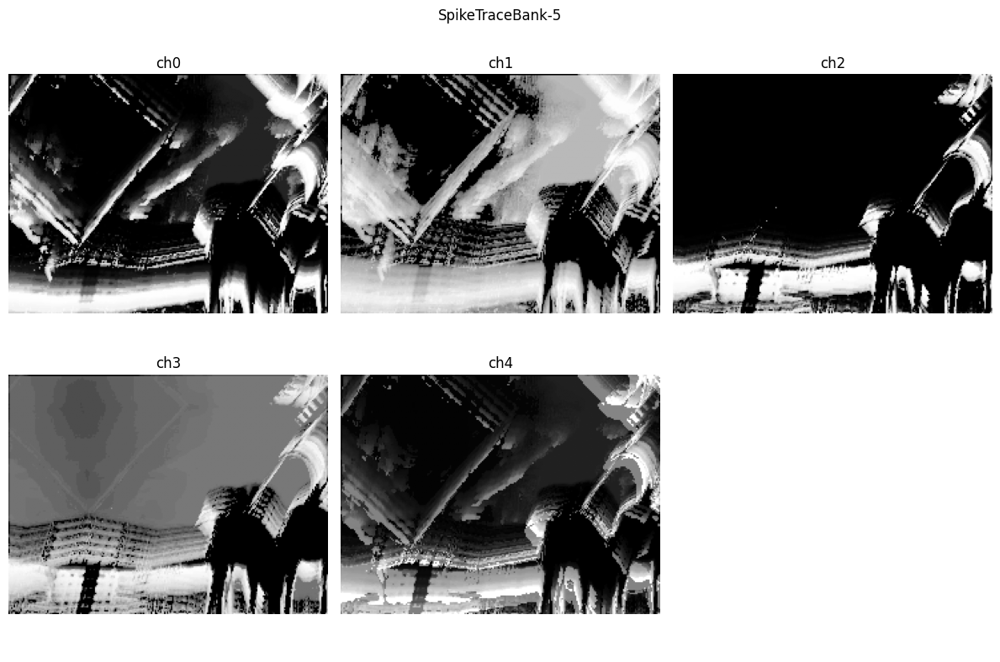

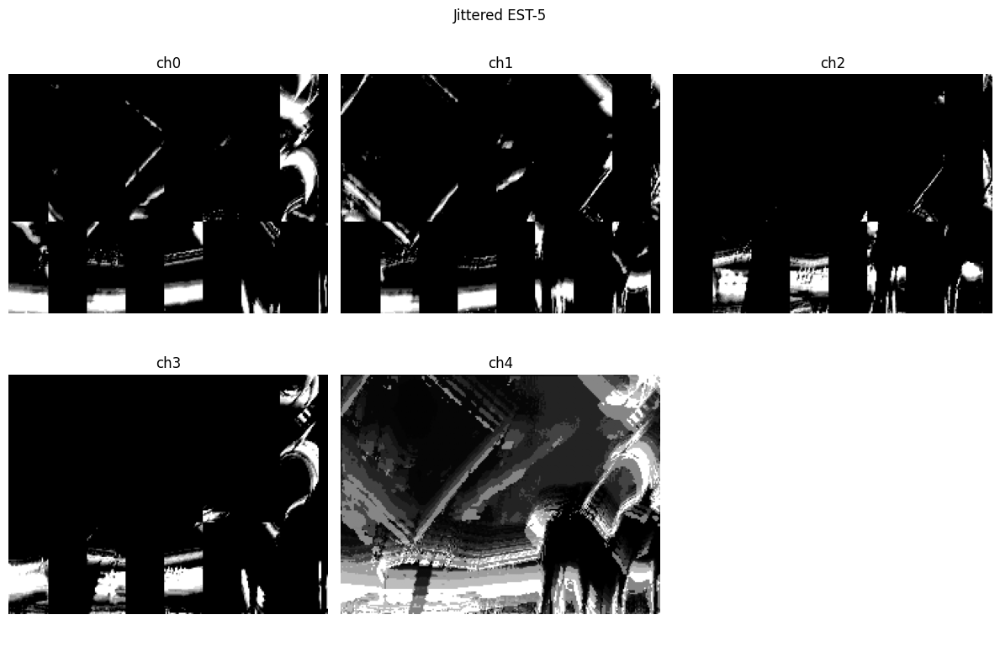

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (1200, 180) to (1200, 192) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).
IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (1200, 180) to (1200, 192) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Wrote vis/enc_trace.mp4
Wrote vis/enc_est.mp4


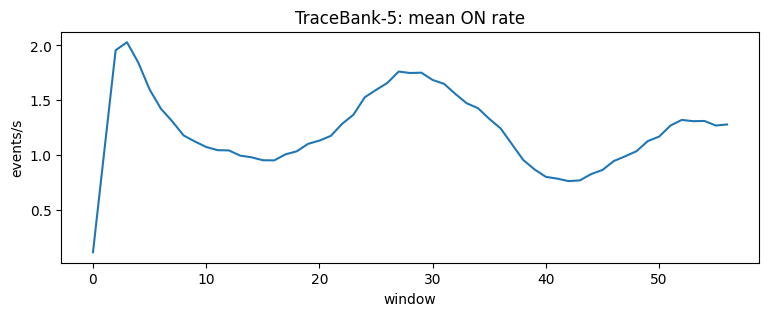

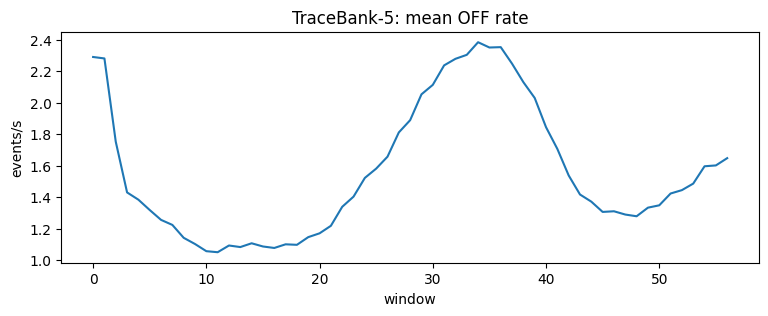

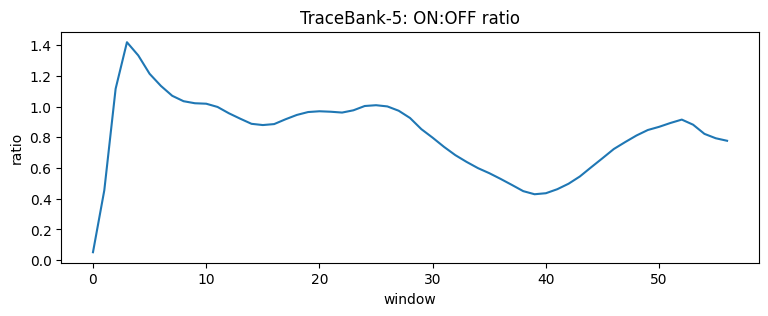

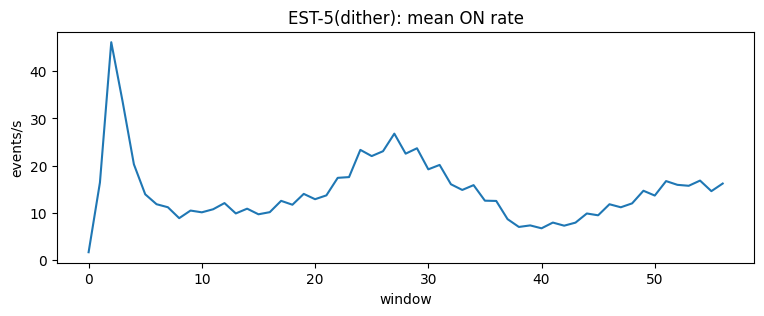

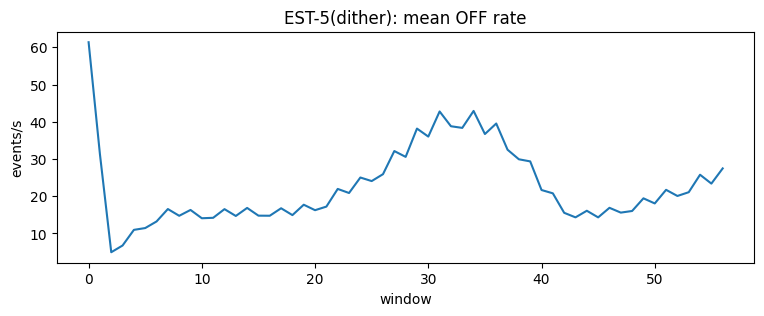

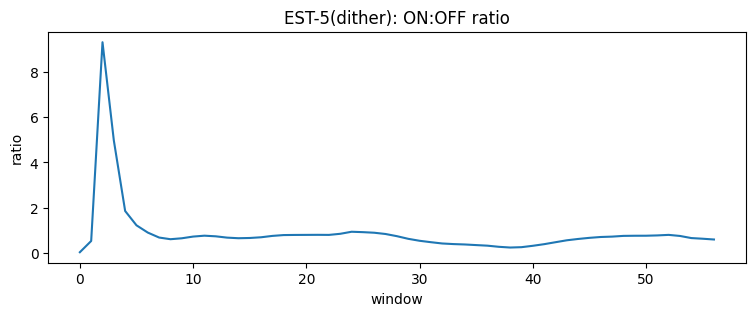

In [ ]:
enc_trace = spike_trace_bank5(
    x, y, t, p, t_bounds, H, W,
    tau_fast_ms=20.0, tau_slow_ms=80.0, tau_ts_ms=50.0,
    asinh_k=0.1  # 0.05–0.2 is a good range; 0 disables
)

enc_est = est5_with_dither(
    x, y, t, p, t_bounds, H, W,
    tau_ts_ms=50.0
)

# move to CPU for plotting if you like
enc_trace_cpu = enc_trace.detach().to("cpu")
enc_est_cpu   = enc_est.detach().to("cpu")


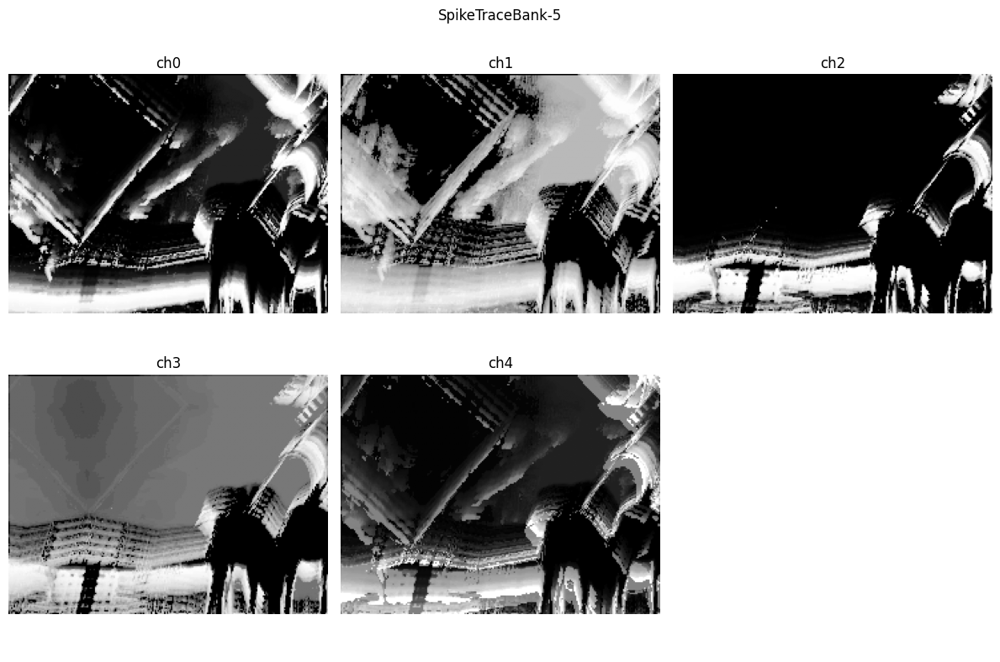

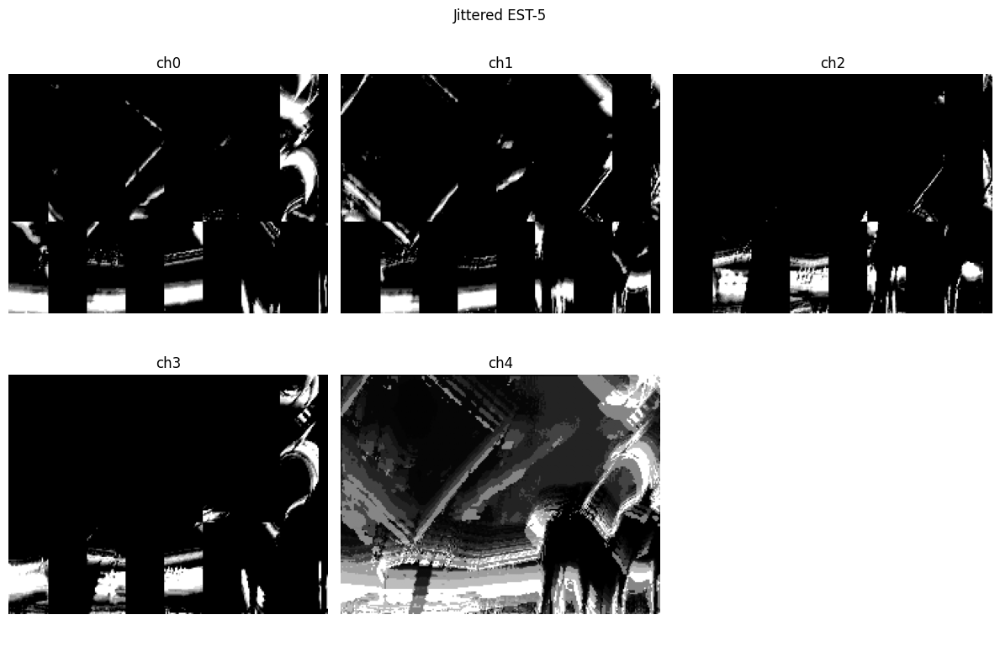

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (1200, 180) to (1200, 192) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Wrote vis/enc_trace.mp4


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (1200, 180) to (1200, 192) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Wrote vis/enc_est.mp4


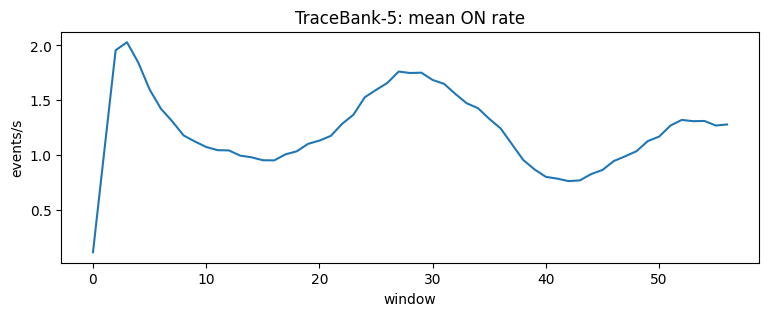

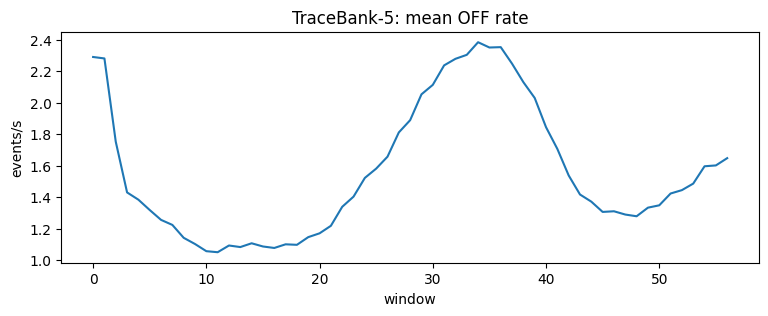

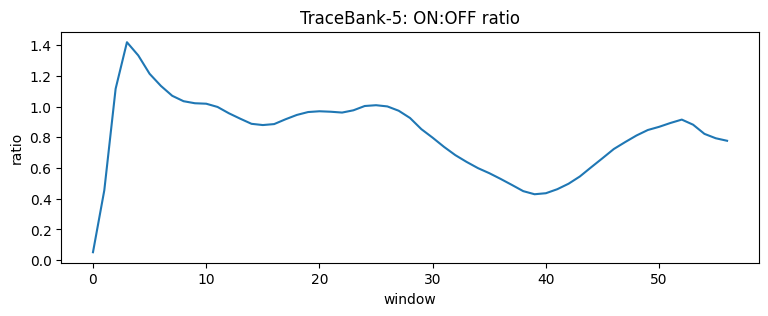

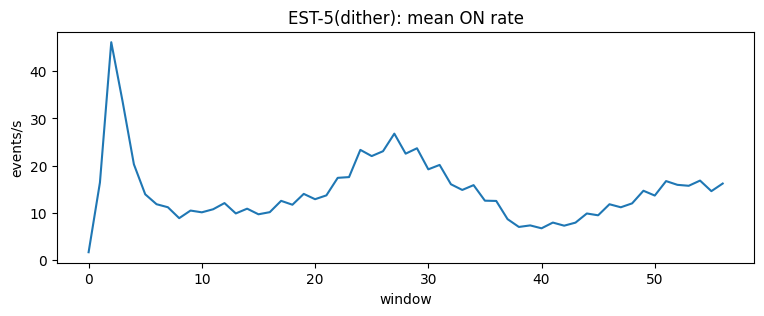

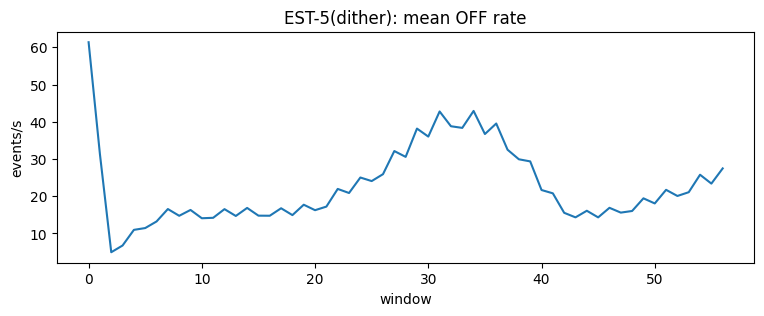

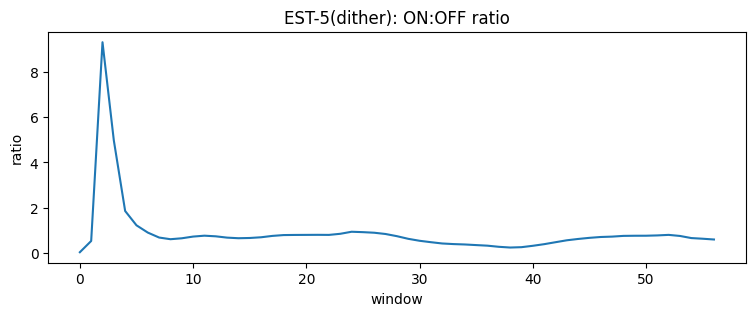

In [44]:
k = 5  # pick a window index with motion
show_window_grid(enc_trace_cpu, k, title="SpikeTraceBank-5")
show_window_grid(enc_est_cpu,   k, title="Jittered EST-5")

# Videos (strip of 5 channels)
os.makedirs("vis", exist_ok=True)
write_encoding_video_safe(enc_trace_cpu, "vis/enc_trace.mp4", fps=30)
write_encoding_video_safe(enc_est_cpu,   "vis/enc_est.mp4",   fps=30)

plot_window_stats(enc_trace_cpu, label="TraceBank-5")
plot_window_stats(enc_est_cpu,   label="EST-5(dither)")

In [45]:
import math, torch

@torch.no_grad()
def spike_trace_bank5_from_rasters(pos, neg, ts_ns, t_bounds,
                                   tau_fast_ms=20.0, tau_slow_ms=80.0, tau_ts_ms=50.0,
                                   asinh_k=0.1):
    """
    pos,neg: (T,H,W) {0,1} tensors
    ts_ns:   (T,) int64 nanoseconds, monotonic
    t_bounds:(K,2) int64 ns; per original-video window [t0,t1)
    Returns (K,5,H,W) float32
    """
    device = pos.device
    T,H,W = pos.shape
    K = t_bounds.shape[0]
    out = torch.zeros((K,5,H,W), dtype=torch.float32, device=device)

    tau_f_ns  = tau_fast_ms * 1e6
    tau_s_ns  = tau_slow_ms * 1e6
    tau_ts_ns = tau_ts_ms   * 1e6

    # window indices in raster time
    s_idx = torch.searchsorted(ts_ns, t_bounds[:,0], right=False)
    e_idx = torch.searchsorted(ts_ns, t_bounds[:,1], right=False)

    # per-pixel running state (spikes-only)
    on_fast  = torch.zeros((H,W), dtype=torch.float32, device=device)
    on_slow  = torch.zeros_like(on_fast)
    off_fast = torch.zeros_like(on_fast)
    off_slow = torch.zeros_like(on_fast)

    very_old = int(ts_ns[0].item()) - 10_000_000_000
    last_on  = torch.full((H,W), very_old, dtype=torch.int64, device=device)
    last_off = torch.full((H,W), very_old, dtype=torch.int64, device=device)

    prev_t1 = int(t_bounds[0,0].item())
    prev_e  = int(s_idx[0].item())

    for k in range(K):
        s = int(s_idx[k].item()); e = int(e_idx[k].item())
        t0 = int(t_bounds[k,0].item()); t1 = int(t_bounds[k,1].item())
        dt_s = max(1e-9, (t1 - t0) * 1e-9)

        # decay traces from previous window end to this window end
        decay_f = math.exp(-(t1 - prev_t1) / tau_f_ns)
        decay_s = math.exp(-(t1 - prev_t1) / tau_s_ns)
        on_fast.mul_(decay_f);  off_fast.mul_(decay_f)
        on_slow.mul_(decay_s);  off_slow.mul_(decay_s)

        # accumulate counts inside this window
        if e > s:
            on_cnt  = pos[s:e].sum(dim=0).float()
            off_cnt = neg[s:e].sum(dim=0).float()
            on_fast.add_(on_cnt);  on_slow.add_(on_cnt)
            off_fast.add_(off_cnt); off_slow.add_(off_cnt)

            # recency: if any spike happened in window, last time becomes t1
            any_on  = (pos[s:e].any(dim=0))
            any_off = (neg[s:e].any(dim=0))
            last_on[any_on]   = t1
            last_off[any_off] = t1

        # write rate-like channels (events/sec)
        out[k,0] = on_fast  / dt_s
        out[k,1] = on_slow  / dt_s
        out[k,2] = off_fast / dt_s
        out[k,3] = off_slow / dt_s

        # recency time-surface at t1
        dt_on  = (t1 - last_on.clamp_max(t1)).to(torch.float32)
        dt_off = (t1 - last_off.clamp_max(t1)).to(torch.float32)
        out[k,4] = 0.5*(torch.exp(-dt_on/tau_ts_ns) + torch.exp(-dt_off/tau_ts_ns))

        prev_t1 = t1
        prev_e  = e

    # optional compressive mapping (log-ish) on rate channels
    if asinh_k > 0:
        out[:,0:4] = torch.asinh(asinh_k * out[:,0:4])
    return out


In [46]:
@torch.no_grad()
def early_late5_from_rasters(pos, neg, ts_ns, t_bounds, tau_ts_ms=50.0, per_pixel_phase=False):
    """
    pos,neg: (T,H,W) {0,1}
    Returns (K,5,H,W) float32 with early/late per polarity + TS.
    If per_pixel_phase=True, uses a deterministic per-pixel split time instead of exact midpoint.
    """
    device = pos.device
    T,H,W = pos.shape
    K = t_bounds.shape[0]
    out = torch.zeros((K,5,H,W), dtype=torch.float32, device=device)

    s_idx = torch.searchsorted(ts_ns, t_bounds[:,0], right=False)
    e_idx = torch.searchsorted(ts_ns, t_bounds[:,1], right=False)

    very_old = int(ts_ns[0].item()) - 10_000_000_000
    last_on  = torch.full((H,W), very_old, dtype=torch.int64, device=device)
    last_off = torch.full((H,W), very_old, dtype=torch.int64, device=device)
    tau_ts_ns = tau_ts_ms * 1e6

    if per_pixel_phase:
        # deterministic phase φ(x,y) in [0,1)
        yy, xx = torch.meshgrid(torch.arange(H, device=device), torch.arange(W, device=device), indexing='ij')
        phi = (((xx*73856093) ^ (yy*19349663)) & 0xFFFFFFFF).float() / (2**32)  # [0,1)
    else:
        phi = None

    for k in range(K):
        s = int(s_idx[k].item()); e = int(e_idx[k].item())
        t0 = int(t_bounds[k,0].item()); t1 = int(t_bounds[k,1].item())
        dt_s = max(1e-9, (t1 - t0) * 1e-9)

        if phi is None:
            t_split = 0.5*(t0 + t1)
            early_mask = ts_ns[s:e] < t_split
        else:
            # per-pixel split time: t0 + φ(x,y)*(t1-t0). We’ll form early/late by summing frames before/after,
            # approximated by nearest frame threshold (fine for your small e-s).
            t_split = t0 + phi*(t1 - t0)  # (H,W)
            # build cumulative sums over time for fast slicing per pixel
            # cum[t] = sum_{i<s+t} pos[i]; so early sum at pixel = cum[e-s_at_px]
            pos_win = pos[s:e].float()  # (M,H,W)
            neg_win = neg[s:e].float()
            # choose time index nearest to per-pixel split
            # map each frame time to index
            idx_times = ts_ns[s:e].to(torch.int64)  # (M,)
            # for each pixel, find largest i with ts[i] < t_split[x,y]
            # O(MHW) via loop might be fine (M small); else approximate by midpoint:
            # fall back to midpoint if complexity is an issue
            early_mask = None  # using midpoint below for simplicity

        if e > s:
            # midpoint split (fast path)
            mid = 0.5*(t0 + t1)
            early_idx = (ts_ns[s:e] < mid).nonzero(as_tuple=False).flatten()
            late_idx  = (ts_ns[s:e] >= mid).nonzero(as_tuple=False).flatten()

            if early_idx.numel() > 0:
                on_e  = pos[s:e][early_idx].sum(dim=0).float()
                off_e = neg[s:e][early_idx].sum(dim=0).float()
            else:
                on_e = off_e = torch.zeros((H,W), dtype=torch.float32, device=device)

            if late_idx.numel() > 0:
                on_l  = pos[s:e][late_idx].sum(dim=0).float()
                off_l = neg[s:e][late_idx].sum(dim=0).float()
            else:
                on_l = off_l = torch.zeros((H,W), dtype=torch.float32, device=device)

            out[k,0] = on_e  / dt_s
            out[k,1] = on_l  / dt_s
            out[k,2] = off_e / dt_s
            out[k,3] = off_l / dt_s

            # recency update
            any_on  = (pos[s:e].any(dim=0))
            any_off = (neg[s:e].any(dim=0))
            last_on[any_on]   = t1
            last_off[any_off] = t1
        else:
            # no spikes: leave ch0..3 zeros

            pass

        dt_on  = (t1 - last_on.clamp_max(t1)).to(torch.float32)
        dt_off = (t1 - last_off.clamp_max(t1)).to(torch.float32)
        out[k,4] = 0.5*(torch.exp(-dt_on/tau_ts_ns) + torch.exp(-dt_off/tau_ts_ns))

    return out


In [50]:
positive = (positive != 0)  # force bool
negative = (negative != 0)


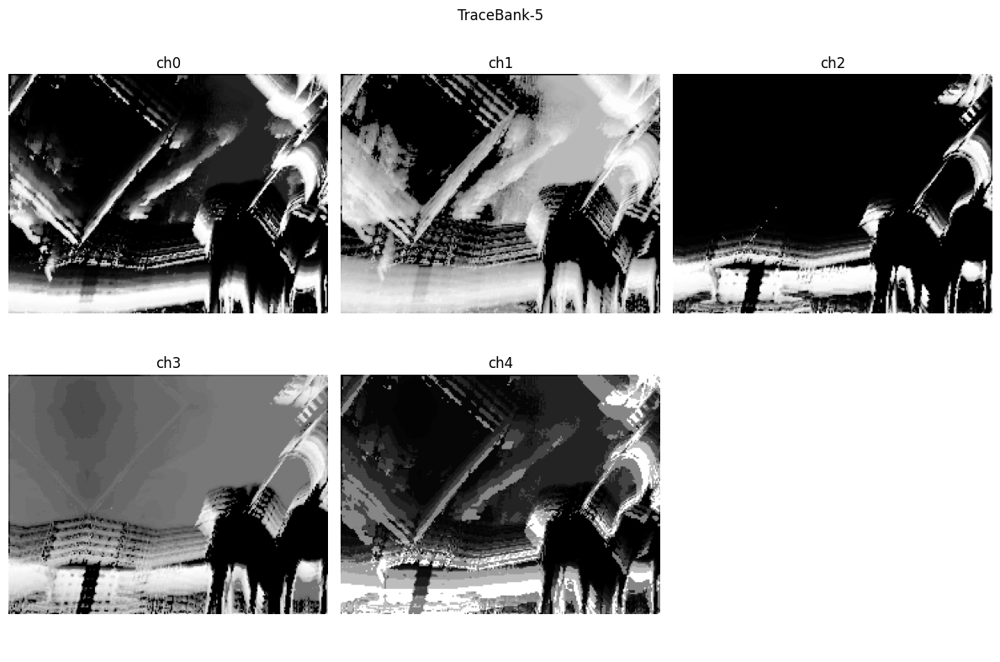

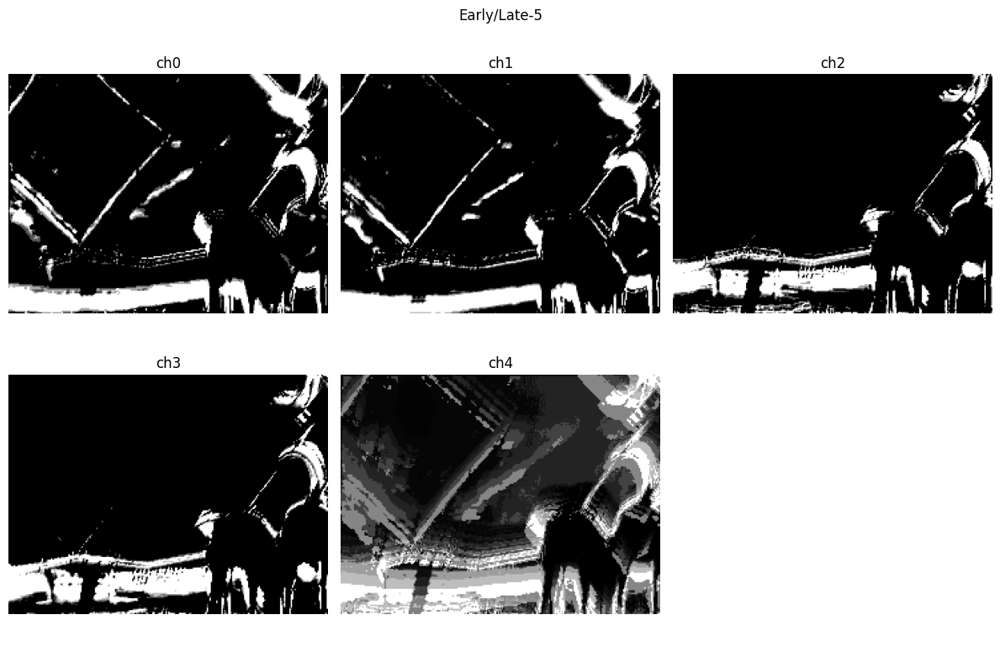

In [52]:
# Build per-original-frame windows:
t_bounds = make_tbounds_from_fps(len(original_frames), params["fps"], t0_ns=int(0)).to(positive.device)
ts_ns = to_ns(timestamps).to(positive.device)


enc_A = spike_trace_bank5_from_rasters(positive.to(device), negative.to(device), ts_ns, t_bounds.to(device),
                                       tau_fast_ms=20, tau_slow_ms=80, tau_ts_ms=50, asinh_k=0.1)
enc_B = early_late5_from_rasters(positive, negative, ts_ns, t_bounds, tau_ts_ms=50)

# Visualize a window k:
show_window_grid(enc_A.to("cpu"), k=5, title="TraceBank-5")
show_window_grid(enc_B.to("cpu"), k=5, title="Early/Late-5")


In [55]:
write_encoding_video_safe(enc_A.cpu(), "vis/enc_trace.mp4", fps=30)
write_encoding_video_safe(enc_B.cpu(),   "vis/enc_est.mp4",   fps=30)

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (1200, 180) to (1200, 192) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Wrote vis/enc_trace.mp4


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (1200, 180) to (1200, 192) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Wrote vis/enc_est.mp4
